In [1]:
# Install everything this notebook needs into the kernel you're running.
# Safe to rerun: already-installed packages are skipped. Restart the kernel after the first install.
%pip install -q pandas numpy matplotlib scipy scikit-learn statsmodels pyarrow jinja2

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\Lenovo\Desktop\fredmac\.venv\Scripts\python.exe -m pip install --upgrade pip


# 01 - Explore the Freddie Mac CRT data

Deals **2019-HQA1** and **2019-HQA2** (high LTV, 81-97%), monthly reports **Feb 2020 to Dec 2022**.

One row = **one loan in one month**. Built by `load_lld.py` into `data/processed/loans_monthly.parquet`.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.2f}".format)

# Works whether the notebook runs from the project root or notebooks/
ROOT = Path.cwd() if Path("data").exists() else Path.cwd().parent
df = pd.read_parquet(ROOT / "data/processed/loans_monthly.parquet")
print(f"{len(df):,} rows, {df.loan_id.nunique():,} loans, {df.period.nunique()} months")
df.head()

5,909,435 rows, 168,850 loans, 35 months


,period,pool,loan_id,state,orig_rate,orig_upb,orig_term,loan_purpose,channel,prop_type,units,occupancy,num_borrowers,first_time_buyer,fico,oltv,ocltv,dti,mi_pct,first_pay_dt,loan_age,dlq_status,curr_upb,eltv,upd_fico1,borrower_assist,pay_deferral,mod_flag,dlq_disaster,zero_bal_code,zero_bal_dt,upb_removal,net_sales_proceeds,mi_credit,taxes_ins,legal_costs,maint_costs,misc_exp,misc_credits,dlq_accrued_int,actual_loss,source_file,calc_loss
0,2020-02-01,19HQA1,19HQA1000002,MD,4.00,"421,000.00",360.00,P,C,PU,1.00,P,2.00,N,791.00,85.00,85.00,39.00,12.00,2018-04-01,22.00,00,"406,100.97",80.00,780.00,NaN,NaN,NaN,NaN,NaN,NaT,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19HQA1_20200201_lld.txt,NaN
1,2020-03-01,19HQA1,19HQA1000002,MD,4.00,"421,000.00",360.00,P,C,PU,1.00,P,2.00,N,791.00,85.00,85.00,39.00,12.00,2018-04-01,23.00,00,"405,433.42",79.00,779.00,NaN,NaN,NaN,NaN,NaN,NaT,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19HQA1_20200301_lld.txt,NaN
2,2020-04-01,19HQA1,19HQA1000002,MD,4.00,"421,000.00",360.00,P,C,PU,1.00,P,2.00,N,791.00,85.00,85.00,39.00,12.00,2018-04-01,24.00,00,"404,763.64",79.00,779.00,NaN,NaN,NaN,NaN,NaN,NaT,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19HQA1_20200401_lld.txt,NaN
3,2020-05-01,19HQA1,19HQA1000002,MD,4.00,"421,000.00",360.00,P,C,PU,1.00,P,2.00,N,791.00,85.00,85.00,39.00,12.00,2018-04-01,25.00,00,"404,091.63",79.00,779.00,NaN,NaN,NaN,NaN,NaN,NaT,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19HQA1_20200501_lld.txt,NaN
4,2020-06-01,19HQA1,19HQA1000002,MD,4.00,"421,000.00",360.00,P,C,PU,1.00,P,2.00,N,791.00,85.00,85.00,39.00,12.00,2018-04-01,26.00,00,"403,417.38",75.00,773.00,NaN,NaN,NaN,NaN,NaN,NaT,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19HQA1_20200601_lld.txt,NaN


## 1. Columns

What's in each column, plus how often it's empty. Codes are explained in `CLAUDE.md` under *Key fields*.

In [3]:
pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "pct_missing": df.isna().mean().mul(100).round(1),
    "example": df.iloc[0],
})

,dtype,pct_missing,example
period,datetime64[us],0.00,2020-02-01 00:00:00
pool,category,0.00,19HQA1
loan_id,str,0.00,19HQA1000002
state,category,0.00,MD
orig_rate,float64,0.00,4.00
orig_upb,float64,0.00,"421,000.00"
orig_term,float64,0.00,360.00
loan_purpose,category,0.00,P
channel,category,0.00,C
prop_type,category,0.00,PU


## 2. Coverage: months per deal

Every loan shows up in every monthly file, **even after it's paid off or sold**. So the row count stays flat over time.

In [4]:
cov = df.groupby(["period", "pool"], observed=True).size().unstack()
print(df.groupby("pool", observed=True).period.agg(["min", "max", "nunique"]))
cov.head()

              min        max  nunique
pool                                 
19HQA1 2020-02-01 2022-12-01       35
19HQA2 2020-02-01 2022-12-01       35


pool,19HQA1,19HQA2
period,,
2020-02-01,86883,81967
2020-03-01,86883,81967
2020-04-01,86883,81967
2020-05-01,86883,81967
2020-06-01,86883,81967


## 3. Feb 2020 baseline: which loans can be modeled?

- **Paid off**: already gone before COVID. Drop them, or they'd count as false "never defaulted".
- **Already late**: behind on payments before COVID. Exclude them (or flag them).
- **Clean**: active and current. This is the modeling population.

In [5]:
base = df[df.period == "2020-02-01"]
active = base.zero_bal_code.isna()
current = base.dlq_status == "00"

summary = pd.Series({
    "all loans": len(base),
    "paid off / exited": (~active).sum(),
    "active but already late": (active & ~current).sum(),
    "clean (active + current)": (active & current).sum(),
})
clean = base[active & current]
summary.to_frame("loans")

,loans
all loans,168850
paid off / exited,30768
active but already late,1656
clean (active + current),136426


## 4. Who are the borrowers? (clean loans, Feb 2020)

- **fico**: credit score at origination (300-850, higher is safer)
- **oltv**: loan as % of home price. 95 means a 5% down payment
- **dti**: monthly debt payments as % of income
- **mi_pct**: % of the loan the mortgage insurer covers

In [6]:
# Validated palette: blue = series 1, orange = series 2
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "lines.linewidth": 2, "font.size": 10,
})

num = ["fico", "oltv", "dti", "orig_rate", "orig_upb", "mi_pct", "eltv", "loan_age"]
clean[num].describe(percentiles=[.05, .5, .95]).T

,count,mean,std,min,5%,50%,95%,max
fico,"136,384.00",743.52,40.78,605.00,673.00,747.00,803.00,829.00
oltv,"136,426.00",92.94,3.87,81.00,85.00,95.00,97.00,97.00
dti,"136,425.00",36.71,8.41,2.00,22.00,38.00,49.00,50.00
orig_rate,"136,426.00",4.73,0.32,3.25,4.25,4.75,5.38,6.62
orig_upb,"136,426.00","231,538.94","107,618.52","21,000.00","86,000.00","212,000.00","432,000.00","825,000.00"
mi_pct,"136,426.00",24.91,6.57,0.00,12.00,25.00,30.00,38.00
eltv,"128,991.00",84.80,8.32,1.00,74.00,86.00,94.00,491.00
loan_age,"136,426.00",18.80,1.83,0.00,16.00,19.00,21.00,58.00


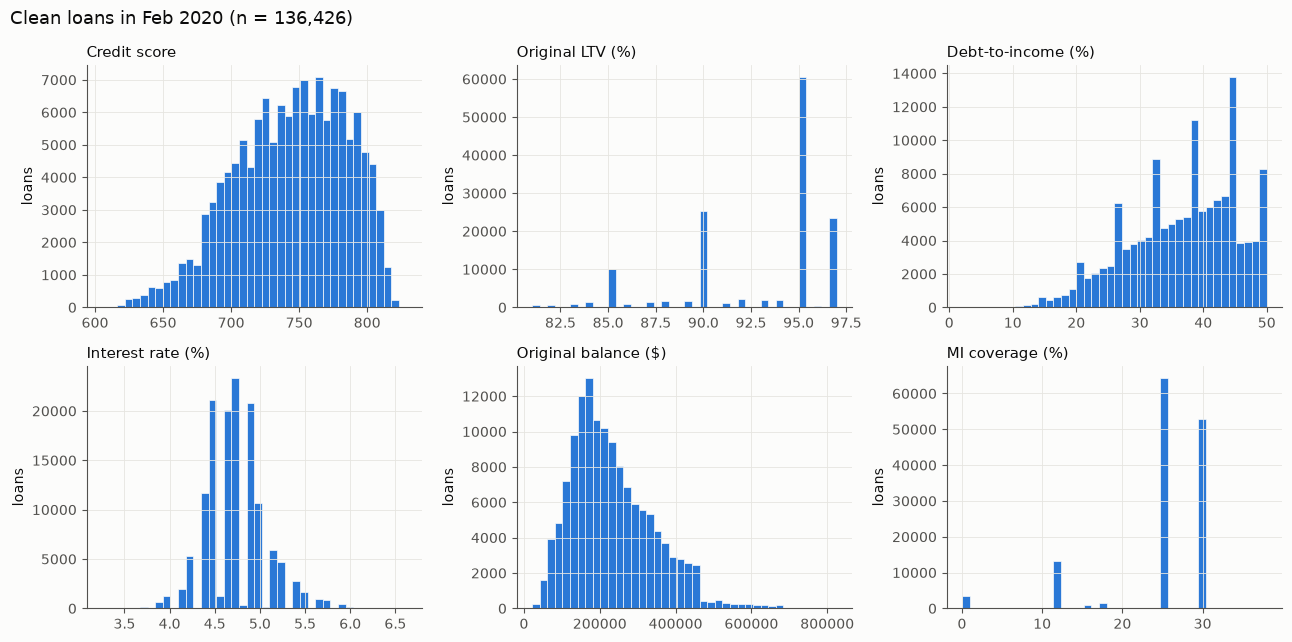

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, col, title in zip(axes.flat,
        ["fico", "oltv", "dti", "orig_rate", "orig_upb", "mi_pct"],
        ["Credit score", "Original LTV (%)", "Debt-to-income (%)",
         "Interest rate (%)", "Original balance ($)", "MI coverage (%)"]):
    ax.hist(clean[col].dropna(), bins=40, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_ylabel("loans")
fig.suptitle("Clean loans in Feb 2020 (n = {:,})".format(len(clean)), x=0.01, ha="left", fontsize=13)
fig.tight_layout()

### Category mix

Shares within the clean loans. Codes: purpose P purchase / C cash-out refi / N no-cash-out refi; occupancy P primary / S second home / I investment; channel R retail / B broker / C correspondent.

In [8]:
for col in ["loan_purpose", "occupancy", "channel", "first_time_buyer", "num_borrowers", "prop_type"]:
    print(f"--- {col}")
    print(clean[col].value_counts(normalize=True, dropna=False).mul(100).round(1).to_string(), "\n")

--- loan_purpose
loan_purpose
P   95.40
N    3.90
C    0.70 

--- occupancy
occupancy
P   98.00
S    1.40
I    0.60 

--- channel
channel
R   51.40
C   39.00
B    9.60 

--- first_time_buyer
first_time_buyer
Y   55.70
N   44.30 

--- num_borrowers
num_borrowers
1.00   58.80
2.00   40.20
3.00    0.90
4.00    0.10
5.00    0.00 

--- prop_type
prop_type
SF   61.80
PU   28.40
CO    9.30
MH    0.40
CP    0.10 



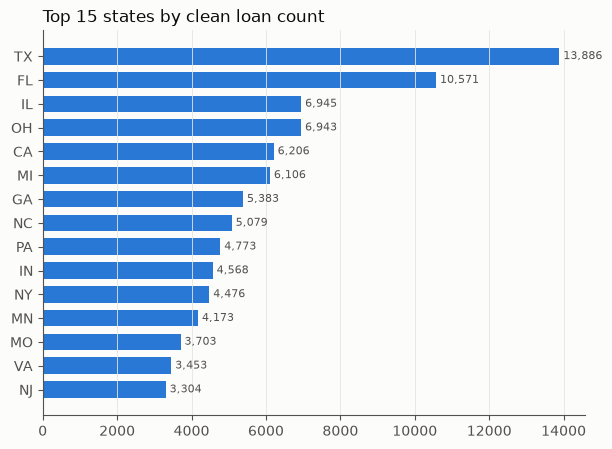

In [9]:
top_states = clean.state.value_counts().head(15).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top_states.index.astype(str), top_states.values, color=BLUE, height=0.7)
ax.set_title("Top 15 states by clean loan count", loc="left")
ax.grid(axis="y", visible=False)
for y, v in enumerate(top_states.values):
    ax.text(v, y, f" {v:,}", va="center", fontsize=8, color=MUTED)

### Who struggled during COVID?

Clean loans split by what happened in the first 12 months (Mar 2020 to Feb 2021), using the same rules as section 6:

- **defaulted**: 90+ days late while **not** in forbearance
- **COVID relief**: went into forbearance (or 90+ late while in it), but never defaulted
- **paid normally**: neither

The table shows medians and shares for each group. Compare the columns: whatever differs between them is a warning sign.

In [10]:
win = df[(df.period > "2020-02-01") & (df.period <= "2021-02-01") & df.loan_id.isin(clean.loan_id)]
late90 = ~win.dlq_status.isin(["00", "01", "02", "XX"]) & win.dlq_status.notna()
forb = win.borrower_assist == "F"

default_ids = set(win.loan_id[late90 & ~forb])
relief_ids = set(win.loan_id[forb | late90]) - default_ids

grp = clean.copy()
grp["outcome"] = "paid normally"
grp.loc[grp.loan_id.isin(relief_ids), "outcome"] = "COVID relief"
grp.loc[grp.loan_id.isin(default_ids), "outcome"] = "defaulted"
order = ["paid normally", "COVID relief", "defaulted"]

def pct(cond):
    """Share of loans in each group where cond(series) is true."""
    return lambda s: cond(s).mean() * 100

g = grp.groupby("outcome")
pd.DataFrame({
    "loans": g.size(),
    "fico (median)": g.fico.median(),
    "oltv (median)": g.oltv.median(),
    "dti (median)": g.dti.median(),
    "orig_rate (median)": g.orig_rate.median(),
    "orig_upb (median)": g.orig_upb.median(),
    "% fico < 680": g.fico.agg(pct(lambda s: s < 680)),
    "% dti > 45": g.dti.agg(pct(lambda s: s > 45)),
    "% single borrower": g.num_borrowers.agg(pct(lambda s: s == 1)),
    "% first-time buyer": g.first_time_buyer.agg(pct(lambda s: s == "Y")),
}).loc[order].T

outcome,paid normally,COVID relief,defaulted
loans,"124,660.00","10,864.00",902.00
fico (median),749.00,725.00,717.00
oltv (median),95.00,95.00,95.00
dti (median),37.00,42.00,41.00
orig_rate (median),4.75,4.75,4.88
orig_upb (median),"209,000.00","235,000.00","229,000.00"
% fico < 680,5.66,11.99,17.29
% dti > 45,13.91,22.94,19.07
% single borrower,58.35,63.30,66.96
% first-time buyer,55.41,59.15,57.98


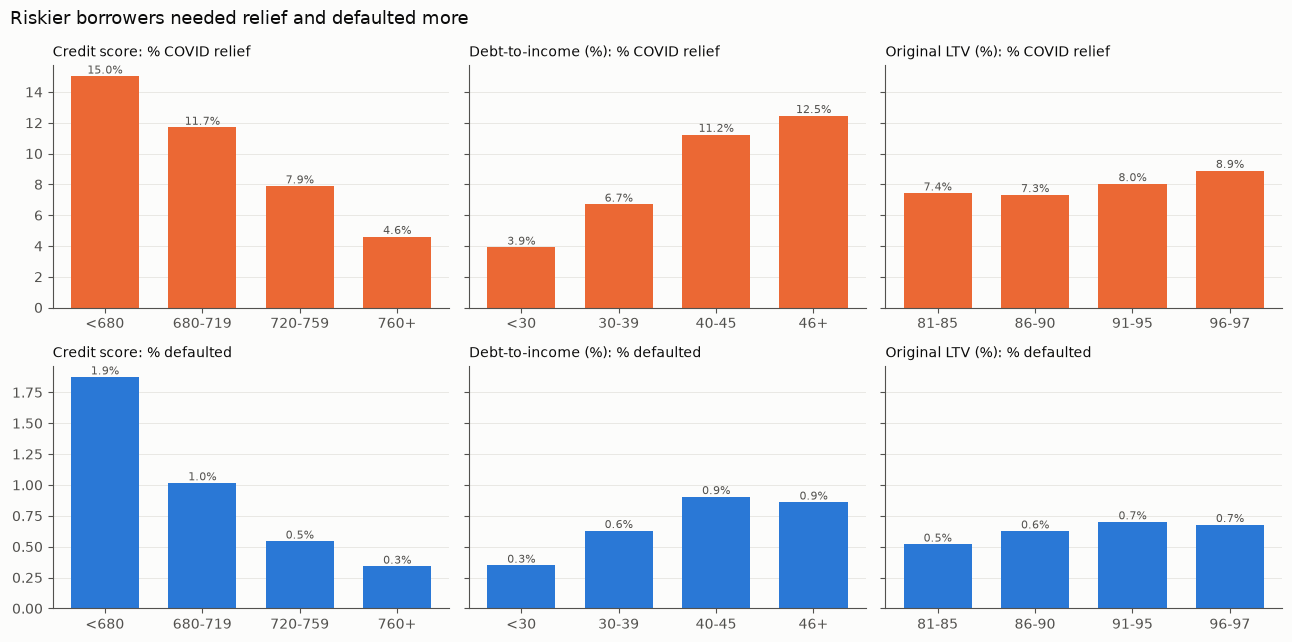

In [11]:
# Rate of each outcome by band: top row = COVID relief, bottom row = defaulted.
# Separate rows because relief (~8%) is ~12x more common than default (~0.7%).
bands = {
    "Credit score": ("fico", [0, 680, 720, 760, 900], ["<680", "680-719", "720-759", "760+"]),
    "Debt-to-income (%)": ("dti", [0, 30, 40, 45, 100], ["<30", "30-39", "40-45", "46+"]),
    "Original LTV (%)": ("oltv", [80, 85, 90, 95, 97], ["81-85", "86-90", "91-95", "96-97"]),
}
# sharey per row: same scale across panels, so bar heights compare fairly
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharey="row")
for j, (title, (col, bins, labels)) in enumerate(bands.items()):
    rates = (grp.groupby(pd.cut(grp[col], bins=bins, labels=labels), observed=True)
                .outcome.value_counts(normalize=True).unstack().mul(100))
    for i, (outcome, color) in enumerate([("COVID relief", ORANGE), ("defaulted", BLUE)]):
        ax = axes[i, j]
        ax.bar(rates.index.astype(str), rates[outcome], color=color, width=0.7)
        ax.grid(axis="x", visible=False)
        ax.set_axisbelow(True)
        for x, v in enumerate(rates[outcome]):
            ax.text(x, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=8, color=MUTED)
        ax.set_title(f"{title}: % {outcome}", loc="left", fontsize=10)
fig.suptitle("Riskier borrowers needed relief and defaulted more", x=0.01, ha="left", fontsize=13)
fig.tight_layout()

In [12]:
# States with the most COVID relief (only states with 1,000+ clean loans)
st = grp.groupby("state", observed=True).agg(
    loans=("loan_id", "size"),
    relief_pct=("outcome", pct(lambda s: s == "COVID relief")),
    default_pct=("outcome", pct(lambda s: s == "defaulted")),
)
st[st.loans >= 1000].sort_values("relief_pct", ascending=False).head(10)

,loans,relief_pct,default_pct
state,,,
NV,1223,15.21,1.39
FL,10571,13.14,0.91
CA,6206,12.58,1.06
NY,4476,11.28,1.05
NJ,3304,11.02,0.97
TX,13886,10.28,0.75
LA,1922,9.83,0.68
MD,2591,9.22,0.54
GA,5383,9.20,0.56


### Do house prices explain the state differences?

FHFA House Price Index (HPI) by 3-digit ZIP, mapped to states with `zip3_state.csv`. Each state gets the **median % price change across its ZIP3 areas** for three windows:

- **pre-COVID**: 2018 Q4 to 2019 Q4 (was the market already hot or cooling?)
- **COVID year**: 2019 Q4 to 2020 Q4 (same window as the outcome)
- **through 2022**: 2019 Q4 to 2022 Q4 (equity cushion by the time losses happen)

Then each window is correlated with the state's **relief %** and **default %** (states with 300+ clean loans). Spearman = rank correlation, so one extreme state can't drive it.

**Caveat:** each ZIP3 area counts equally, not weighted by how many of our loans sit there. Only ~45 states, so treat p-values as rough.

In [13]:
import numpy as np
from scipy import stats

hpi = pd.read_csv(ROOT / "data/FHFA House Price Index - Sheet1.csv")
hpi.columns = ["zip3", "year", "qtr", "index", "index_type"]
hpi["zip3"] = hpi.zip3.astype(str).str.zfill(3)
z2s = pd.read_csv(ROOT / "data/zip3_state.csv", dtype=str)[["zip3", "state"]]

# One column per quarter-end we need, one row per ZIP3
q = hpi.assign(q=hpi.year.astype(str) + "Q" + hpi.qtr.astype(str))
q = q[q.q.isin(["2018Q4", "2019Q4", "2020Q4", "2022Q4"])].pivot(index="zip3", columns="q", values="index")
chg = pd.DataFrame({
    "hpi_pre_covid": q["2019Q4"] / q["2018Q4"] - 1,
    "hpi_covid_year": q["2020Q4"] / q["2019Q4"] - 1,
    "hpi_thru_2022": q["2022Q4"] / q["2019Q4"] - 1,
}).mul(100).join(z2s.set_index("zip3"), how="inner")

state_hpi = chg.groupby("state")[["hpi_pre_covid", "hpi_covid_year", "hpi_thru_2022"]].median()
sh = st[st.loans >= 300].join(state_hpi, how="inner")
print(f"{len(sh)} states with 300+ clean loans and HPI data")

rows = []
for h in ["hpi_pre_covid", "hpi_covid_year", "hpi_thru_2022"]:
    for o in ["relief_pct", "default_pct"]:
        rho, p = stats.spearmanr(sh[h], sh[o])
        rows.append({"hpi window": h, "outcome": o, "spearman_rho": rho, "p_value": p})
corr = pd.DataFrame(rows)
corr

44 states with 300+ clean loans and HPI data


,hpi window,outcome,spearman_rho,p_value
0,hpi_pre_covid,relief_pct,-0.15,0.32
1,hpi_pre_covid,default_pct,0.15,0.33
2,hpi_covid_year,relief_pct,-0.04,0.79
3,hpi_covid_year,default_pct,0.23,0.14
4,hpi_thru_2022,relief_pct,0.02,0.92
5,hpi_thru_2022,default_pct,0.16,0.30


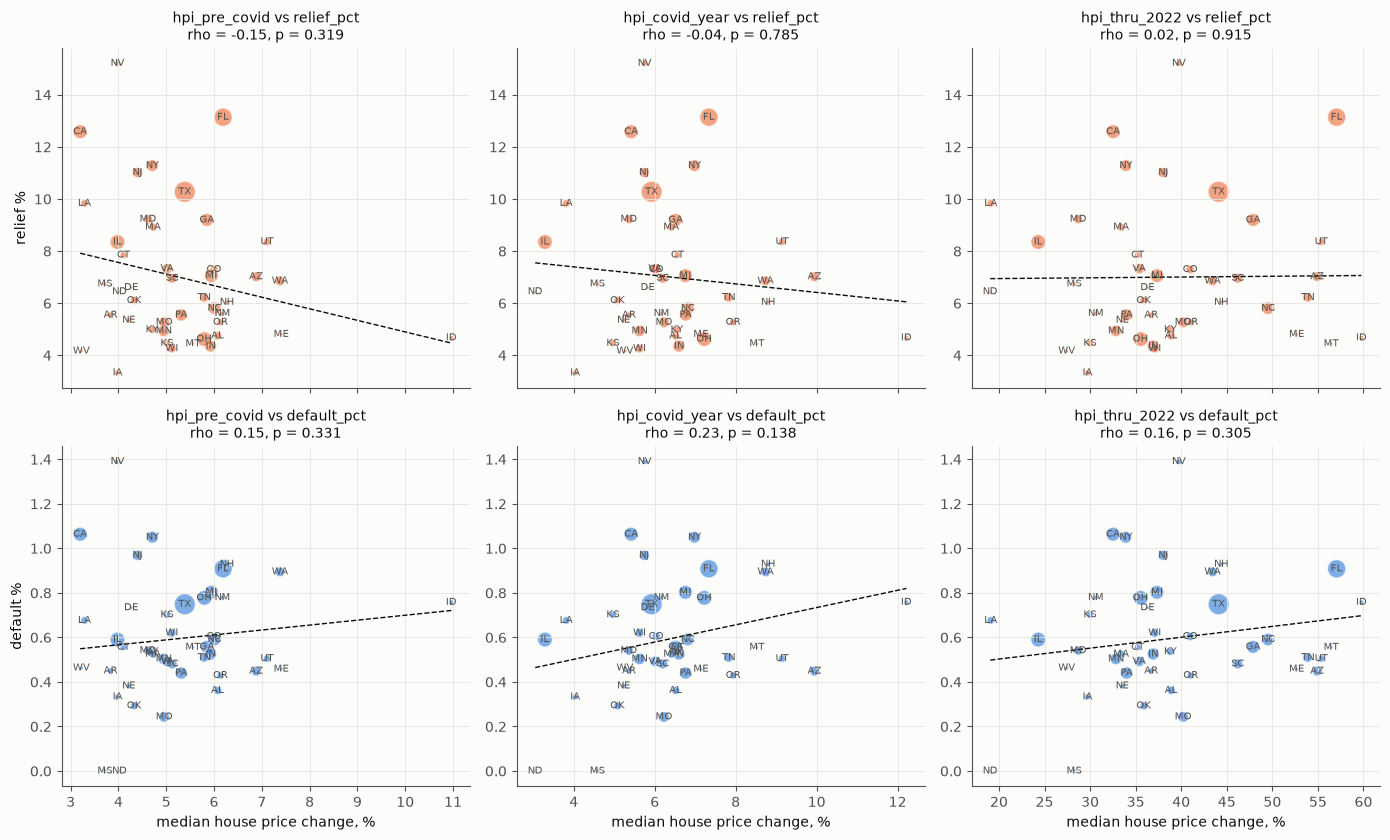

In [14]:
# Each dot = one state, sized by number of clean loans. Line = straight-line fit, for the eye only.
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5), sharex="col")
for j, h in enumerate(["hpi_pre_covid", "hpi_covid_year", "hpi_thru_2022"]):
    for i, (o, color) in enumerate([("relief_pct", ORANGE), ("default_pct", BLUE)]):
        ax = axes[i, j]
        ax.scatter(sh[h], sh[o], s=sh.loans / 60, color=color, alpha=0.6, edgecolor="white")
        for s, r in sh.iterrows():
            ax.annotate(str(s), (r[h], r[o]), fontsize=7, color=MUTED, ha="center", va="center")
        b, a = np.polyfit(sh[h], sh[o], 1)
        xs = np.linspace(sh[h].min(), sh[h].max(), 2)
        ax.plot(xs, a + b * xs, color=INK, lw=1, ls="--")
        r = corr[(corr["hpi window"] == h) & (corr.outcome == o)].iloc[0]
        ax.set_title(f"{h} vs {o}\nrho = {r.spearman_rho:.2f}, p = {r.p_value:.3f}", fontsize=10)
        ax.set_ylabel(o.replace("_pct", " %") if j == 0 else "")
    axes[1, j].set_xlabel("median house price change, %")
plt.tight_layout()
plt.show()

**Takeaways (this run)**

44 states with 300+ clean loans.

- **No meaningful link at the state level.** Every Spearman correlation is weak (**rho -0.15 to 0.23**) and **none is significant** (all p > 0.13).
- **Prices rose almost everywhere**, so there was little bad news to spread around: **+3% to +12%** in the COVID year and **+19% to +60%** through 2022. Almost every borrower still had equity, which helps explain why losses were sparse (section 7).
- **The high-relief states don't share a price story.** NV, FL, CA, NY and NJ all sit at the top for relief %, yet span the whole price range (CA ~5%, FL ~7% in the COVID year). Job losses in tourism and service work (NV, FL) and early lockdowns (NY, NJ) are more likely drivers than home prices.
- **Small states are noisy.** MS and ND show 0% default on a few hundred loans; don't read anything into them.
- **What this means for the model:** state-level HPI is unlikely to add much. Loan-level `eltv` (current LTV, which already reflects local prices) is the better way to capture equity, and section 11 found even that not significant.

## 5. What COVID did

Share of **active** loans each month that were 90+ days late, and share in **forbearance** (payments paused with permission).

The two lines move together. That's the core problem: in 2020-2021, most "90+ days late" loans were in forbearance, not actually defaulting.

,active_loans,pct_90plus,pct_forbearance
period,,,
2020-02-01,138082,0.29,0.05
2020-05-01,124077,0.45,0.26
2020-08-01,105538,5.22,8.12
2020-11-01,90549,5.66,8.03
2021-02-01,78043,6.15,7.71
2021-05-01,66332,5.94,7.21
2021-08-01,57376,5.29,6.11
2021-11-01,50233,4.57,4.49
2022-02-01,45410,4.10,2.05


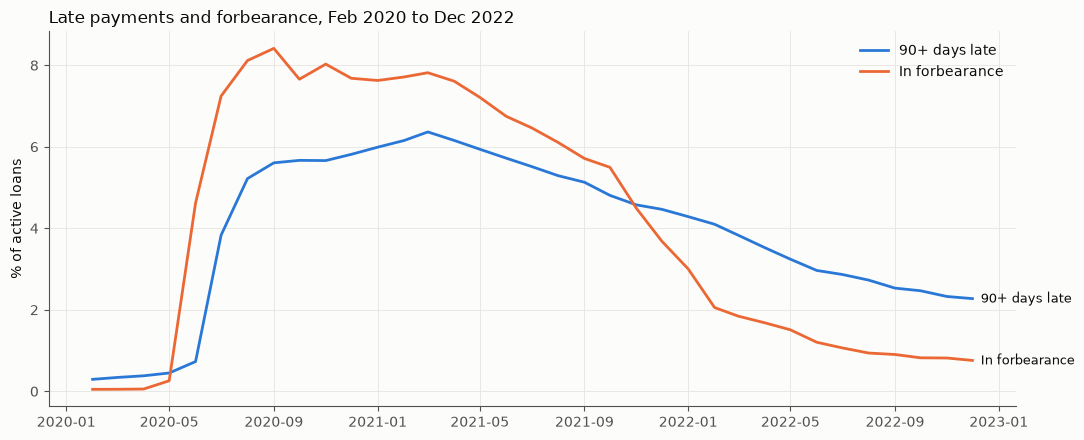

In [15]:
act = df[df.zero_bal_code.isna()]
late90 = ~act.dlq_status.isin(["00", "01", "02", "XX"]) & act.dlq_status.notna()

trend = pd.DataFrame({
    "active_loans": act.groupby("period").size(),
    "pct_90plus": late90.groupby(act.period).mean() * 100,
    "pct_forbearance": (act.borrower_assist == "F").groupby(act.period).mean() * 100,
})

fig, ax = plt.subplots(figsize=(11, 4.5))
for col, color, label in [("pct_90plus", BLUE, "90+ days late"),
                          ("pct_forbearance", ORANGE, "In forbearance")]:
    ax.plot(trend.index, trend[col], color=color, label=label)
    ax.annotate(label, (trend.index[-1], trend[col].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK, fontsize=9)
ax.set_ylabel("% of active loans")
ax.set_title("Late payments and forbearance, Feb 2020 to Dec 2022", loc="left")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
trend.iloc[::3]

## 6. Target preview: raw vs COVID-adjusted defaults

Clean Feb 2020 loans, watched for 12 months (Mar 2020 to Feb 2021).

- **raw**: ever 90+ days late
- **adjusted**: ever 90+ days late **while not in forbearance**

Caveat: forbearance could last up to 18 months, so a lot of "still late after forbearance ended" happens **after** this window.

In [16]:
win = df[(df.period > "2020-02-01") & (df.period <= "2021-02-01") & df.loan_id.isin(clean.loan_id)]
w90 = ~win.dlq_status.isin(["00", "01", "02", "XX"]) & win.dlq_status.notna()

raw_ids = set(win.loan_id[w90])
adj_ids = set(win.loan_id[w90 & (win.borrower_assist != "F")])
n = len(clean)
pd.DataFrame({
    "loans": [len(raw_ids), len(adj_ids)],
    "rate_%": [len(raw_ids) / n * 100, len(adj_ids) / n * 100],
}, index=["raw 90+", "adjusted 90+ (not forbearance)"])

,loans,rate_%
raw 90+,7810,5.72
adjusted 90+ (not forbearance),902,0.66


## 7. Losses

A **credit exit** is when a loan ends badly: short sale (03), foreclosure sale (02), foreclosed home sold (09, "REO sold"), or note sale (15).

`calc_loss` is an approximate loss: unpaid balance + costs - sale proceeds - insurance payout.

**Gotchas:**
- An exited loan keeps showing up in later monthly files, so we keep only its **first** exit row.
- Some exits happened **before Feb 2020** (check `zero_bal_dt`). They aren't COVID losses.
- Some losses are **negative**: sale proceeds + insurance covered more than what was owed.

In [17]:
exits = (df[df.calc_loss.notna()]
         .sort_values("period")
         .drop_duplicates("loan_id"))
print(f"{len(exits):,} loans with a credit exit (from {df.calc_loss.notna().sum():,} raw rows)")

exits["severity_%"] = exits.calc_loss / exits.upb_removal * 100
exits.groupby(["pool", "zero_bal_code"], observed=True).agg(
    loans=("loan_id", "size"),
    total_loss=("calc_loss", "sum"),
    median_loss=("calc_loss", "median"),
    median_severity_pct=("severity_%", "median"),
)

106 loans with a credit exit (from 2,112 raw rows)


loans   total_loss  median_loss  median_severity_pct
pool   zero_bal_code                                                      
19HQA1 03                43 1,051,217.95    17,964.75                10.36
       09                24   308,787.08     3,268.61                 2.83
19HQA2 03                20   350,953.82    15,994.04                 6.18
       09                19   208,841.69     7,567.55                 9.31

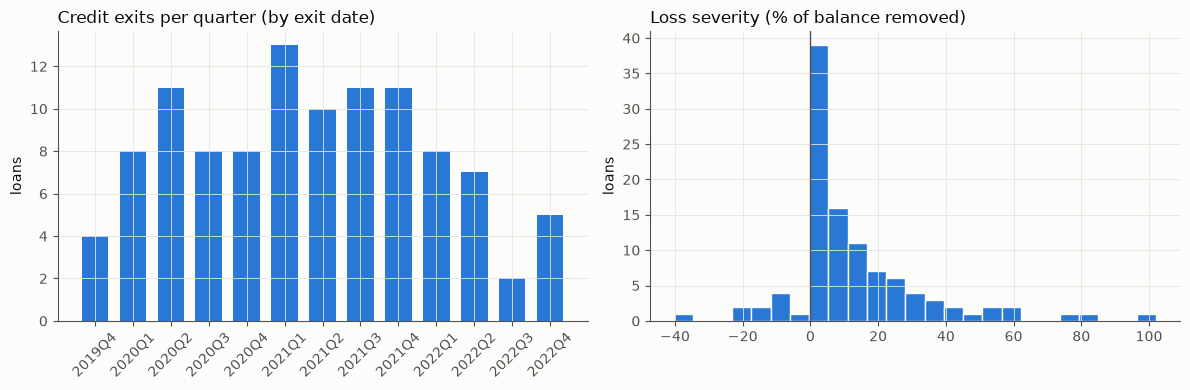

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Use the actual exit date (zero_bal_dt), not the report month: some exits happened before Feb 2020
by_q = exits.zero_bal_dt.dt.to_period("Q").value_counts().sort_index()
axes[0].bar(by_q.index.astype(str), by_q.values, color=BLUE, width=0.7)
axes[0].tick_params(axis="x", rotation=45)
axes[0].set_title("Credit exits per quarter (by exit date)", loc="left")
axes[0].set_ylabel("loans")

axes[1].hist(exits["severity_%"].dropna(), bins=25, color=BLUE, edgecolor="#fcfcfb")
axes[1].axvline(0, color=MUTED, linewidth=1)
axes[1].set_title("Loss severity (% of balance removed)", loc="left")
axes[1].set_ylabel("loans")
fig.tight_layout()

## 8. Look up one loan

Shows a loan's month-by-month history. By default it picks a loan that went into forbearance.

In [19]:
def loan_history(loan_id):
    cols = ["period", "dlq_status", "borrower_assist", "pay_deferral", "dlq_disaster",
            "mod_flag", "curr_upb", "eltv", "upd_fico1", "zero_bal_code", "calc_loss"]
    return df.loc[df.loan_id == loan_id, cols].sort_values("period")

example = df.loc[df.borrower_assist == "F", "loan_id"].iloc[0]
print("loan:", example)
loan_history(example)

loan: 19HQA1000004


,period,dlq_status,borrower_assist,pay_deferral,dlq_disaster,mod_flag,curr_upb,eltv,upd_fico1,zero_bal_code,calc_loss
70,2020-02-01,00,NaN,NaN,NaN,NaN,"96,176.40",77.00,485.00,NaN,NaN
71,2020-03-01,00,NaN,NaN,NaN,NaN,"96,050.28",75.00,485.00,NaN,NaN
72,2020-04-01,01,NaN,NaN,NaN,NaN,"96,050.28",75.00,485.00,NaN,NaN
73,2020-05-01,02,NaN,NaN,NaN,NaN,"96,050.28",75.00,485.00,NaN,NaN
74,2020-06-01,01,F,NaN,Y,NaN,"95,796.42",71.00,534.00,NaN,NaN
75,2020-07-01,00,F,NaN,NaN,NaN,"95,540.39",71.00,534.00,NaN,NaN
76,2020-08-01,01,F,NaN,Y,NaN,"95,540.39",71.00,534.00,NaN,NaN
77,2020-09-01,00,F,C,NaN,NaN,"96,225.98",72.00,568.00,NaN,NaN
78,2020-10-01,00,NaN,P,NaN,NaN,"96,064.60",72.00,568.00,NaN,NaN
79,2020-11-01,00,NaN,P,NaN,NaN,"95,902.53",72.00,568.00,NaN,NaN


## 9. Feature importance test

Which Feb 2020 features actually help predict a COVID-adjusted default (target from section 6)?

**Method: permutation importance.**
1. Train a quick gradient-boosted tree model on **19HQA1** loans.
2. Score it on **19HQA2** loans it never saw (out-of-deal test).
3. Shuffle one feature at a time in the test set and measure how much **PR-AUC** drops. A big drop means the model leans on that feature. Zero or negative means it adds nothing.

Why PR-AUC: defaults are under 1% of loans, so accuracy is meaningless (predicting "nobody defaults" scores 99%+).

In [20]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, roc_auc_score

FEATURES = [
    "fico", "upd_fico1", "dti", "num_borrowers", "first_time_buyer",  # borrower strength
    "oltv", "eltv",                                                    # equity
    "orig_rate", "orig_upb", "loan_age", "orig_term",                  # loan terms
    "loan_purpose", "occupancy", "channel", "prop_type", "units",      # kind of loan
    "state",                                                           # where
]

X = clean.set_index("loan_id")[FEATURES + ["pool"]].copy()
X["fico_change"] = X.upd_fico1 - X.fico    # credit getting worse before COVID?
X["equity_change"] = X.oltv - X.eltv       # how much the home gained in value
y = pd.Series(X.index.isin(adj_ids).astype(int), index=X.index)

# Drop unused category levels so the tree model sees a clean category list
for c in X.select_dtypes("category"):
    X[c] = X[c].cat.remove_unused_categories()

train, test = X.pool == "19HQA1", X.pool == "19HQA2"
X = X.drop(columns="pool")
pd.DataFrame({
    "loans": [train.sum(), test.sum()],
    "defaults": [y[train].sum(), y[test].sum()],
    "default_rate_%": [y[train].mean() * 100, y[test].mean() * 100],
}, index=["train (HQA1)", "test (HQA2)"])

,loans,defaults,default_rate_%
train (HQA1),70429,468,0.66
test (HQA2),65997,434,0.66


In [21]:
# Missing values (eltv, upd_fico1) are handled natively by this model; no fill needed
model = HistGradientBoostingClassifier(
    learning_rate=0.05, max_iter=300, max_leaf_nodes=15, min_samples_leaf=200,
    l2_regularization=1.0, categorical_features="from_dtype", random_state=0,
)
model.fit(X[train], y[train])

p = model.predict_proba(X[test])[:, 1]
print(f"Test PR-AUC : {average_precision_score(y[test], p):.3f}  (random guessing = {y[test].mean():.3f})")
print(f"Test ROC-AUC: {roc_auc_score(y[test], p):.3f}  (random guessing = 0.500)")

Test PR-AUC : 0.022  (random guessing = 0.007)
Test ROC-AUC: 0.725  (random guessing = 0.500)


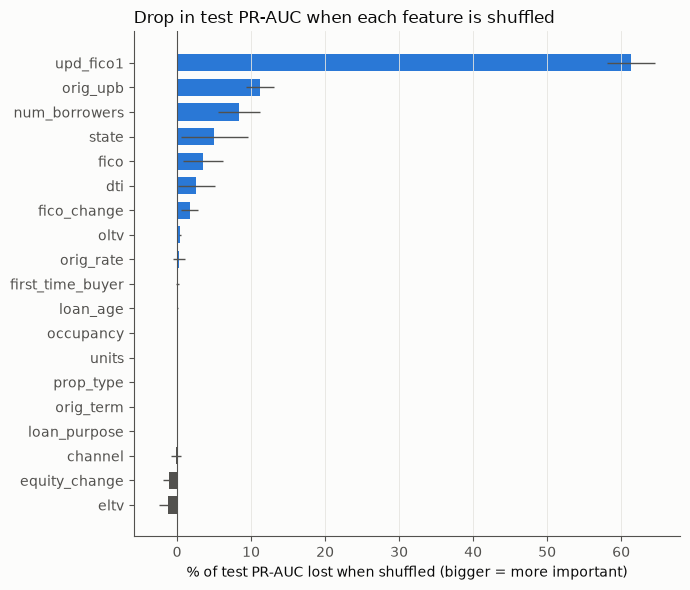

,pct_pr_auc_lost,std_pct
upd_fico1,61.30,3.30
orig_upb,11.20,1.90
num_borrowers,8.40,2.80
state,5.00,4.50
fico,3.60,2.70
dti,2.60,2.50
fico_change,1.70,1.10
oltv,0.40,0.20
orig_rate,0.20,0.80
first_time_buyer,0.00,0.20


In [22]:
pi = permutation_importance(
    model, X[test], y[test], scoring="average_precision",
    n_repeats=10, random_state=0, n_jobs=-1,
)
# Express each drop as % of the model's test PR-AUC, easier to read than 0.00x numbers
base_pr = average_precision_score(y[test], p)
imp = (pd.DataFrame({"pr_auc_drop": pi.importances_mean, "std": pi.importances_std}, index=X.columns)
         .mul(100 / base_pr).rename(columns={"pr_auc_drop": "pct_pr_auc_lost", "std": "std_pct"})
         .sort_values("pct_pr_auc_lost"))

fig, ax = plt.subplots(figsize=(7, 6))
colors = [BLUE if v > 0 else MUTED for v in imp.pct_pr_auc_lost]
ax.barh(imp.index, imp.pct_pr_auc_lost, xerr=imp.std_pct, color=colors, height=0.7,
        error_kw={"ecolor": MUTED, "lw": 1})
ax.axvline(0, color=MUTED, lw=0.8)
ax.set_title("Drop in test PR-AUC when each feature is shuffled", loc="left")
ax.set_xlabel("% of test PR-AUC lost when shuffled (bigger = more important)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
imp.sort_values("pct_pr_auc_lost", ascending=False).round(1)

**How to read this**

- **Bars with error lines crossing zero** are noise: the model doesn't reliably use that feature.
- **Correlated features share credit.** `fico`, `upd_fico1` and `fico_change` carry overlapping information, as do `oltv`, `eltv` and `equity_change`. Shuffling one leaves the others to cover for it, so each can look *less* important than the group really is. Judge them as a group before dropping any.
- **This is a quick check model**, not the final PD model, and it uses the preliminary 12-month target from section 6.

**Takeaways (this run)**

- **The model is weak but real:** test PR-AUC **0.022** vs **0.007** for random guessing (about 3x), ROC-AUC **0.725**. It holds up on a deal it never saw.
- **Refreshed credit score dominates:** shuffling `upd_fico1` wipes out **~61%** of PR-AUC. How the borrower looked in early 2020 matters far more than at origination (`fico` ~4%).
- **Next tier:** loan size (`orig_upb`, ~11%), one vs two borrowers (`num_borrowers`, ~8%), `state` (~5%, but noisy).
- **Adds nothing here:** occupancy, units, property type, term, loan purpose, channel, first-time buyer, loan age.
- **Surprise: equity features (`eltv`, `equity_change`) score slightly negative.** Likely because house prices rose in 2020, so equity didn't separate who defaulted within 12 months. Expect equity to matter more for **loss severity** than for default.
- **Caveat:** only ~900 defaults and a preliminary 12-month target. Re-run this after the final default definition before dropping any feature.

## 10. Struggling vs paid normally: which features differ significantly?

Clean Feb 2020 loans, watched Mar 2020 to Feb 2021. Three struggling groups, each compared against the same baseline:

- **defaulted**: 90+ days late while **not** in forbearance (the COVID-adjusted target from section 6)
- **90+ days late**: ever 90+ days without payment, in forbearance or not (the raw target from section 6)
- **forbearance**: entered forbearance at least once
- **baseline = paid normally**: never 90+ late and never in forbearance

The groups overlap (a loan 90+ late while in forbearance counts in both of the last two), so each one is tested on its own against the baseline.

Each feature gets a statistical test:
- **Numbers** (fico, dti, ...): Mann-Whitney U test, compares the two groups without assuming a bell curve. **Effect** = how often a random struggling loan has a higher value than a random paid-normally loan, scaled -1 to +1 (0 = no difference, negative = struggling group lower).
- **Categories** (state, channel, ...): chi-square test. **Effect** = Cramer's V, 0 to 1 (0 = the group's rate is the same in every level).

**p_adj** is Bonferroni-corrected (p x number of tests, across all three groups) because we test many features at once. **Significant** = p_adj < 0.05.

**Chart:** one bar per group, faded = not significant.

**Read the effect, not just the p-value.** With 100k+ loans even tiny differences come out "significant". The effect size tells you whether the difference is big enough to matter.

In [23]:
from scipy import stats
import numpy as np

# Groups use the 12-month window from section 6 (win, w90)
forb_ids = set(win.loan_id[win.borrower_assist == "F"])
GROUPS = {"defaulted": adj_ids, "90+ days late": raw_ids, "forbearance": forb_ids}

d = clean.copy()
d["fico_change"] = d.upd_fico1 - d.fico               # credit worsening before COVID
d["single_borrower"] = np.where(d.num_borrowers == 1, "Y", "N")
base = d[~d.loan_id.isin(raw_ids | forb_ids)]          # paid normally

NUMERIC = ["upd_fico1", "fico_change", "fico", "orig_rate", "dti", "orig_upb",
           "eltv", "oltv", "mi_pct", "loan_age"]
CATEG = ["single_borrower", "first_time_buyer", "loan_purpose", "occupancy",
         "channel", "prop_type", "state"]

def compare(grp, name):
    """Test every feature: grp vs paid normally."""
    both = pd.concat([grp.assign(hit=True), base.assign(hit=False)])
    rows = []
    for c in NUMERIC:
        a, b = grp[c].dropna().astype(float), base[c].dropna().astype(float)
        u, p = stats.mannwhitneyu(a, b)
        rows.append({"feature": c, "test": "Mann-Whitney", "value": f"median {a.median():,.1f}",
                     "baseline": f"median {b.median():,.1f}",
                     "effect": 2 * u / (len(a) * len(b)) - 1, "p": p})
    for c in CATEG:
        s = both[c].astype("object").fillna("missing")
        tab = pd.crosstab(s, both.hit)
        tab = tab[tab.sum(axis=1) >= 100]              # tiny levels make chi-square unreliable
        chi2, p, _, _ = stats.chi2_contingency(tab)
        rate = tab[True] / tab.sum(axis=1) * 100
        rows.append({"feature": c, "test": "chi-square",
                     "value": f"high: {rate.idxmax()} {rate.max():.1f}%, low: {rate.idxmin()} {rate.min():.1f}%",
                     "baseline": "",                # rates above are already relative to it
                     "effect": np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1))), "p": p})
    return pd.DataFrame(rows).assign(group=name)

res = pd.concat([compare(d[d.loan_id.isin(ids)], name) for name, ids in GROUPS.items()])
res["p_adj"] = (res.p * len(res)).clip(upper=1)        # Bonferroni across all tests
res["significant"] = res.p_adj < 0.05

print(f"paid normally (baseline): {len(base):,} loans")
for name, ids in GROUPS.items():
    print(f"{name}: {len(ids):,} loans")

# One block of columns per group; rows sorted by the defaulted effect
wide = res.set_index(["feature", "group"])[["value", "effect", "p_adj", "significant"]].unstack("group")
wide = wide.swaplevel(axis=1)[list(GROUPS)]
wide.insert(0, ("paid normally", "baseline"), res[res.group == "defaulted"].set_index("feature").baseline)
wide = wide.reindex(res[res.group == "defaulted"].set_index("feature").effect.abs().sort_values(ascending=False).index)
fmt = {(g, "effect"): "{:+.3f}" for g in GROUPS} | {(g, "p_adj"): "{:.1e}" for g in GROUPS}
wide.style.format(fmt)

paid normally (baseline): 124,660 loans
defaulted: 902 loans
90+ days late: 7,810 loans
forbearance: 11,595 loans


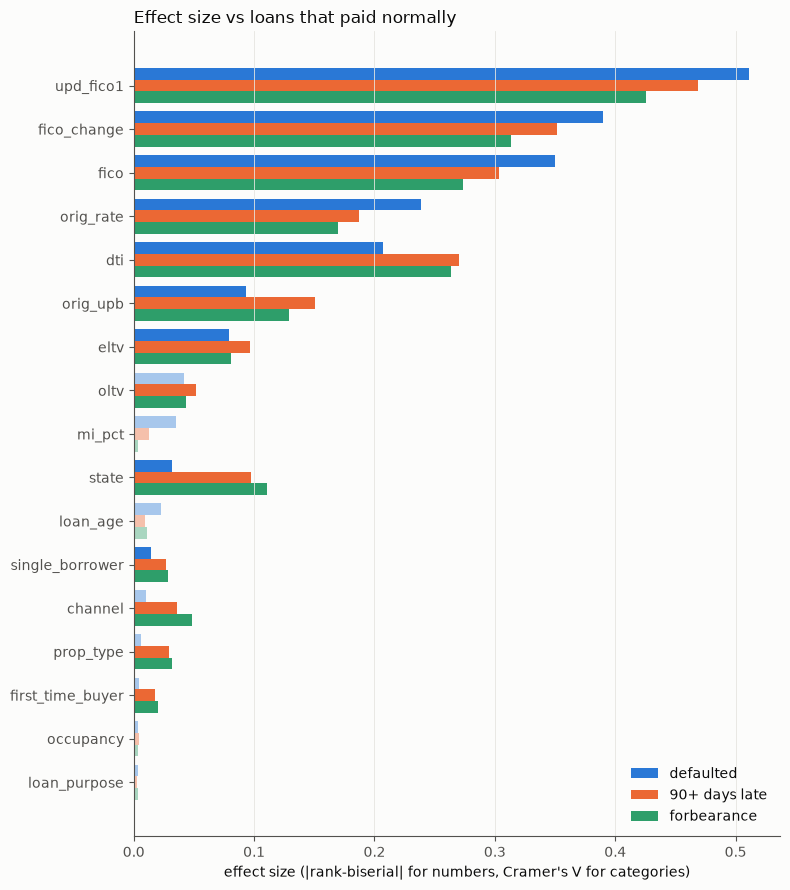

group,defaulted,90+ days late,forbearance
feature,,,
upd_fico1,-0.511,-0.468,-0.425
fico_change,-0.390,-0.352,-0.314
fico,-0.350,-0.303,-0.274
orig_rate,+0.239,+0.187,+0.170
dti,+0.207,+0.270,+0.263
orig_upb,+0.093,+0.150,+0.129
eltv,+0.079,+0.097,+0.081
oltv,+0.042,+0.052,+0.043
mi_pct,+0.035,+0.013,+0.003


In [24]:
# Effect size per feature, one bar per group. Faded bar = not significant.
GREEN = "#2e9e6a"
colors = {"defaulted": BLUE, "90+ days late": ORANGE, "forbearance": GREEN}
feats = wide.index[::-1]
y = np.arange(len(feats))
h = 0.27
fig, ax = plt.subplots(figsize=(8, 9))
for k, (name, color) in enumerate(colors.items()):
    r = res[res.group == name].set_index("feature").loc[feats]
    ax.barh(y + (1 - k) * h, r.effect.abs(), height=h, color=color, label=name)
    for yy, (v, s) in enumerate(zip(r.effect.abs(), r.significant)):
        if not s:  # overdraw non-significant bars faded so the colour still identifies the group
            ax.barh(yy + (1 - k) * h, v, height=h, color="#fcfcfb", alpha=0.6)
ax.set_yticks(y, feats)
ax.set_title("Effect size vs loans that paid normally", loc="left")
ax.set_xlabel("effect size (|rank-biserial| for numbers, Cramer's V for categories)")
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

# Direction for numeric features: negative = struggling group lower
direction = (res[res.test == "Mann-Whitney"]
             .pivot(index="feature", columns="group", values="effect")
             .loc[NUMERIC, list(GROUPS)])
direction.style.format("{:+.3f}").background_gradient(cmap="RdBu", vmin=-0.5, vmax=0.5)

**Takeaways (this run)**

Group sizes: **902 defaulted**, **7,810 ever 90+ days late**, **11,595 entered forbearance**, vs **124,660 paid normally**.

- **Credit score is the top warning sign for all three groups.** Median refreshed `upd_fico1`: **681** defaulted, **695** 90+ late, **703** forbearance, vs **756** paid normally. All three groups' scores had also **dropped 20-30 points since origination** (`fico_change`), while paid-normally loans rose +4.
- **Credit score separates defaulters most sharply** (effect **-0.51**, vs -0.47 and -0.43). Defaulters are the weakest-credit slice of the struggling borrowers.
- **Debt-to-income matters more for the 90+ late and forbearance groups** (effect **+0.27 / +0.26** vs +0.21 for defaulted; median dti **42** vs 37). Stretched-budget borrowers tended to take forbearance rather than default outright.
- **Loan size and state matter more for 90+ late and forbearance than for defaulted.** Nevada stands out: **16.6%** of its loans in this comparison entered forbearance, and 12.5% went 90+ late.
- **Broker channel, PUD property type, single borrower and first-time buyer** are significant for 90+ late and forbearance but tiny (effect under 0.05). For defaulted, only single borrower passes; the group is small (902), so the tests have less power.
- **No difference in any group:** `mi_pct`, `loan_age`, occupancy, loan purpose.
- **Caveat:** the groups overlap (most 90+ late loans were also in forbearance), so their results look alike partly because they share loans. Also, these are one-feature-at-a-time tests, so correlated features (e.g. fico and orig_rate) can each look significant because of the same underlying cause.

## 11. Logistic regression: what predicts paying vs defaulting?

One model with **all the features at once**. Target: **0 = defaulted** (90+ days late while not in forbearance, Mar 2020 to Feb 2021), **1 = every other clean loan**. The payers include:
- **continuous payers**: never 90+ late, never in forbearance (includes loans that paid off early)
- **successful payers via relief**: entered forbearance (or were 90+ late only while in it) but never defaulted

Setup:
- **Number features are standardized** (1 step = 1 standard deviation), so their effects are comparable. `fico_change` is left out because it is exactly `upd_fico1 - fico`, which would make the model unsolvable.
- **Category features** are compared against their most common level (the "reference"). Levels with under 200 loans are folded into the reference.
- **State is left out:** ~50 levels with only 902 defaults would give mostly noise.
- Rows missing `upd_fico1` or `eltv` are dropped.

How to read the **odds ratio (OR)**:
- **OR > 1** = more likely to **pay**. **OR < 1** = more likely to **default**.
- Numbers: OR per **1 standard deviation** increase. Categories: OR vs the reference level.
- Unlike section 10, each effect here is **with all other features held fixed**, so a feature only shows up if it adds something the others don't already explain.

In [25]:
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score

LNUM = ["upd_fico1", "fico", "orig_rate", "dti", "orig_upb", "eltv", "oltv", "mi_pct", "loan_age"]
LCAT = ["single_borrower", "first_time_buyer", "loan_purpose", "occupancy", "channel", "prop_type"]

m = d.copy()                                         # all clean Feb 2020 loans
m["paid"] = (~m.loan_id.isin(adj_ids)).astype(int)
m["payer_type"] = np.select([m.paid == 0, m.loan_id.isin(base.loan_id)],
                            ["defaulted", "continuous payer"], "successful payer via relief")
print(m.payer_type.value_counts().to_string())
print()
n_before = len(m)
m = m.dropna(subset=LNUM)
for c in LNUM:
    m[c] = m[c].astype(float)

# Category levels: most common = reference; rare levels folded into it
REF = {}
for c in LCAT:
    s = m[c].astype("object").fillna("missing")
    counts = s.value_counts()
    REF[c] = counts.index[0]
    m[c] = s.where(s.map(counts) >= 200, REF[c])
LEVELS = {c: [l for l in m[c].value_counts().index if l != REF[c]] for c in LCAT}
MU, SD = m[LNUM].mean(), m[LNUM].std()

def design(df):
    """Standardized numbers + one dummy per non-reference level + intercept."""
    X = (df[LNUM] - MU) / SD
    for c in LCAT:
        for l in LEVELS[c]:
            X[f"{c}={l}"] = (df[c] == l).astype(float)
    return sm.add_constant(X, has_constant="add")

logit = sm.Logit(m.paid, design(m)).fit(disp=0)
m["p_paid"] = logit.predict(design(m))

print(f"{len(m):,} loans ({m.paid.eq(0).sum():,} defaulted), {n_before - len(m):,} dropped for missing values")
print(f"pseudo R2 {logit.prsquared:.3f} | AUC {roc_auc_score(m.paid, m.p_paid):.3f} (0.5 = coin flip, 1 = perfect)")
print("references:", ", ".join(f"{c}={v}" for c, v in REF.items()))

ci = np.exp(logit.conf_int())
coef = pd.DataFrame({"odds_ratio": np.exp(logit.params), "ci_low": ci[0], "ci_high": ci[1],
                     "p": logit.pvalues}).drop("const")
coef["significant"] = coef.p < 0.05
coef["1 SD ="] = SD.reindex(coef.index)          # step size behind each number OR
coef["reading"] = np.where(~coef.significant, "no clear effect",
                           np.where(coef.odds_ratio > 1, "more likely to pay", "more likely to default"))
coef = coef.reindex(np.log(coef.odds_ratio).abs().sort_values(ascending=False).index)
coef.style.format({"odds_ratio": "{:.2f}", "ci_low": "{:.2f}", "ci_high": "{:.2f}", "p": "{:.1e}", "1 SD =": "{:,.1f}"}, na_rep="")

payer_type
continuous payer               124660
successful payer via relief     10864
defaulted                         902



128,795 loans (846 defaulted), 7,631 dropped for missing values


pseudo R2 0.091 | AUC 0.771 (0.5 = coin flip, 1 = perfect)
references: single_borrower=Y, first_time_buyer=Y, loan_purpose=P, occupancy=P, channel=R, prop_type=SF


,odds_ratio,ci_low,ci_high,p,significant,1 SD =,reading
upd_fico1,1.88,1.77,1.99,8.1e-99,True,61.2,more likely to pay
single_borrower=N,1.81,1.56,2.10,9.2e-15,True,,more likely to pay
loan_purpose=N,0.78,0.54,1.11,1.7e-01,False,,no clear effect
orig_upb,0.78,0.73,0.83,2.0e-13,True,"106,964.2",more likely to default
dti,0.82,0.76,0.89,1.3e-06,True,8.4,more likely to default
fico,1.17,1.08,1.28,2.5e-04,True,40.7,more likely to pay
mi_pct,0.90,0.81,1.00,4.3e-02,True,6.6,more likely to default
orig_rate,0.90,0.84,0.97,5.9e-03,True,0.3,more likely to default
channel=B,0.91,0.73,1.13,4.0e-01,False,,no clear effect
occupancy=S,0.92,0.45,1.88,8.3e-01,False,,no clear effect


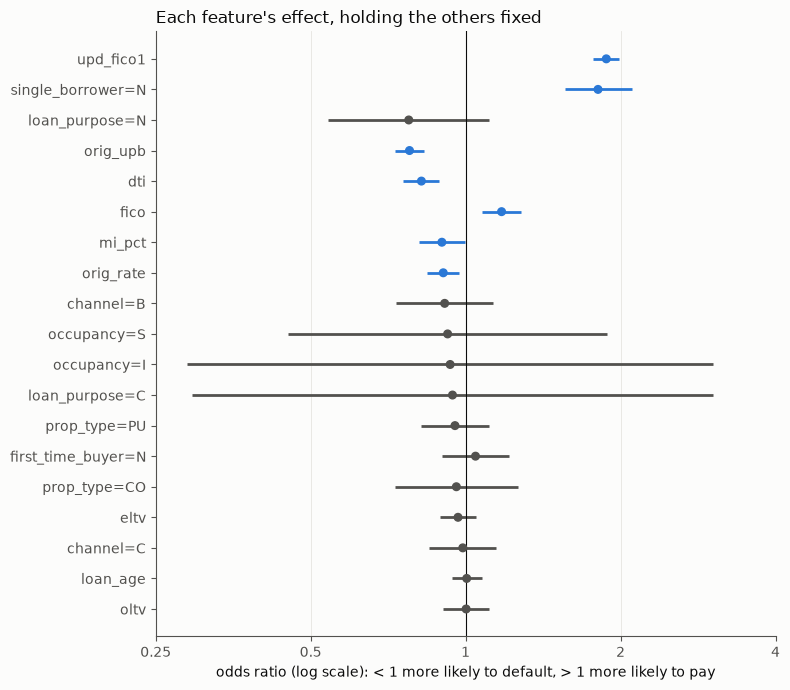

In [26]:
# Odds ratios with 95% confidence intervals. Right of 1 = more likely to pay. Grey = not significant.
plot = coef.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
cols = [BLUE if s else MUTED for s in plot.significant]
ax.hlines(range(len(plot)), plot.ci_low, plot.ci_high, color=cols, lw=2)
ax.scatter(plot.odds_ratio, range(len(plot)), color=cols, s=30, zorder=3)
ax.axvline(1, color=INK, lw=0.8)
ax.set_xscale("log")
ax.minorticks_off()
ax.set_xticks([0.25, 0.5, 1, 2, 4], ["0.25", "0.5", "1", "2", "4"])
ax.set_yticks(range(len(plot)), plot.index)
ax.set_xlabel("odds ratio (log scale): < 1 more likely to default, > 1 more likely to pay")
ax.set_title("Each feature's effect, holding the others fixed", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

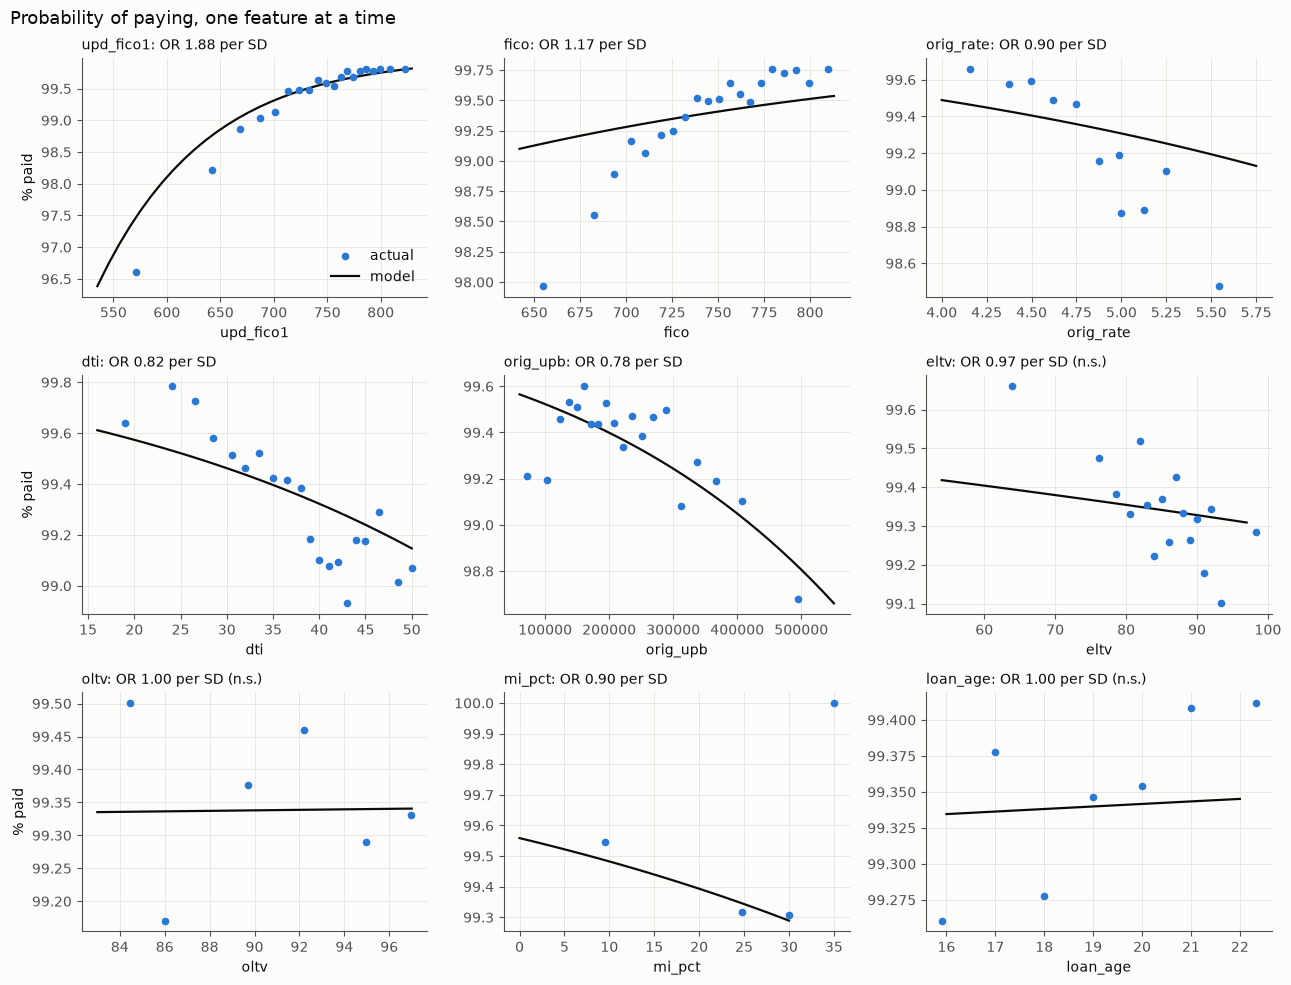

In [27]:
# One chart per number feature.
# Dots = actual % paid in 20 equal-size buckets.
# Line = model's average prediction if every loan had this value of the feature, everything
# else left as it really is. Where line and dots disagree, other features explain the pattern.
sample = m.sample(20_000, random_state=0)            # sample keeps the 9 x 30 re-predictions fast

def avg_pred(feat, values):
    out = []
    for v in values:
        s = sample.copy()
        s[feat] = v
        out.append(logit.predict(design(s)).mean() * 100)
    return out

fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, feat in zip(axes.flat, LNUM):
    b = m.groupby(pd.qcut(m[feat], 20, duplicates="drop"), observed=True).agg(x=(feat, "mean"), rate=("paid", "mean"))
    lo, hi = m[feat].quantile([0.01, 0.99])
    xs = np.linspace(lo, hi, 30)
    ax.scatter(b.x, b.rate * 100, color=BLUE, s=20, zorder=3, label="actual")
    ax.plot(xs, avg_pred(feat, xs), color=INK, lw=1.6, label="model")
    o = coef.loc[feat]
    ax.set_title(f"{feat}: OR {o.odds_ratio:.2f} per SD" + ("" if o.significant else " (n.s.)"),
                 loc="left", fontsize=10)
    ax.set_xlabel(feat)
axes[0, 0].legend(frameon=False, loc="lower right")
for ax in axes[:, 0]:
    ax.set_ylabel("% paid")
fig.suptitle("Probability of paying, one feature at a time", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
plt.show()

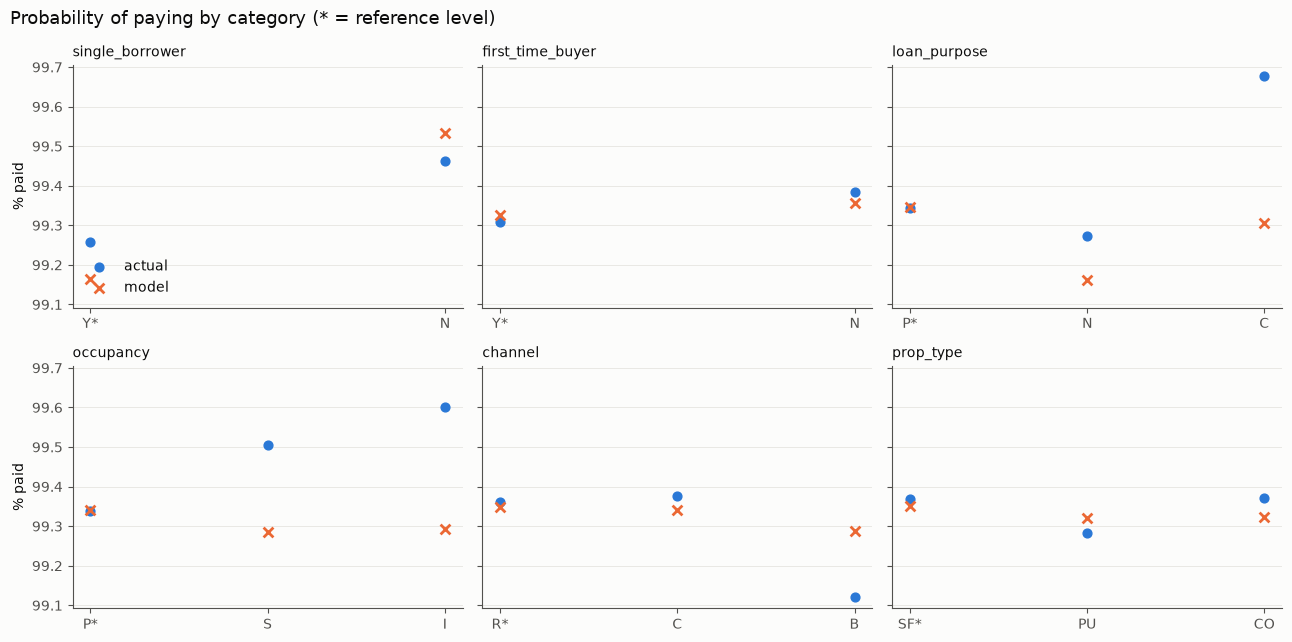

In [28]:
# One chart per category feature: actual % paid per level (dot) and the model's average
# prediction if every loan had that level (cross). Reference level marked with *.
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharey=True)
for ax, feat in zip(axes.flat, LCAT):
    levels = [REF[feat]] + LEVELS[feat]
    actual = m.groupby(feat).paid.mean().loc[levels] * 100
    pred = avg_pred(feat, levels)
    x = np.arange(len(levels))
    ax.scatter(x, actual, color=BLUE, s=40, zorder=3, label="actual")
    ax.scatter(x, pred, color=ORANGE, marker="x", s=50, zorder=3, label="model")
    ax.set_xticks(x, [f"{l}*" if l == REF[feat] else str(l) for l in levels])
    ax.set_title(feat, loc="left", fontsize=10)
    ax.grid(axis="x", visible=False)
axes[0, 0].legend(frameon=False, loc="lower left")
for ax in axes[:, 0]:
    ax.set_ylabel("% paid")
fig.suptitle("Probability of paying by category (* = reference level)", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
plt.show()

**Takeaways (this run)**

Model: **128,795 loans, 846 defaulted** (7,631 dropped for missing `upd_fico1`/`eltv`). Payers before dropping: **124,660 continuous** + **10,864 successful via relief**. **AUC 0.77**, pseudo R2 0.09. The AUC is measured on the same loans the model was fit on, so it's a bit optimistic.

- **Refreshed credit score is by far the strongest:** every **~61 points** higher `upd_fico1` multiplies the odds of paying by **1.88**. The model line follows the dots closely.
- **Two borrowers pay much more reliably than one:** OR **1.81** vs single-borrower loans (the most common type here). One income is less of a cushion when a job is lost.
- **Bigger loans and higher debt-to-income lean toward default:** OR **0.78** per ~$107k of `orig_upb`, OR **0.82** per ~8 points of `dti`.
- **Origination `fico` shrinks once refreshed score is in the model:** its dots slope steeply, but the model line is much flatter (OR 1.17). Most of what `fico` says is already in `upd_fico1`.
- **Small but real:** higher `orig_rate` (OR 0.90 per 0.3 points) and `mi_pct` (OR 0.90, borderline p = 0.04).
- **No clear effect with the others held fixed:** `eltv`, `oltv`, `loan_age`, channel, property type, first-time buyer, occupancy, loan purpose. Occupancy and loan purpose have very wide intervals because few defaults fall outside the reference level.
- **Effects are a little weaker than when relief borrowers were left out**, because those borrowers are riskier than continuous payers yet count as payers here. The ranking of features doesn't change.